# Assignment 3: Optimization Techniques

**Author:** Albert Kabore, PhD student in AI

## Introduction

The placement of distribution centers affects facility operating costs, inbound
transportation, outbound delivery distances, and the ability to serve customer demand.
This assignment examines these decisions together for a hypothetical regional network
supplied through a Chatham County location representing the Savannah area.

This exercise compares county-level warehouse-location and transportation models for
six southeastern states using Census and BTS data. Pallet demand, capacities, most
costs, and service thresholds are scenario assumptions. County centers represent
locations; they are not warehouse addresses. The time screen uses a modeled
county-pair median and does not guarantee actual deliveries.

The objectives are to select distribution-center counties, minimize weekly network
cost, meet demand within capacity and time restrictions, and evaluate inventory
coverage through a stated cycle-stock policy. The analysis compares linear and
integer programming, greedy search, simulated annealing, and gradient-based location
fitting. Validation, sensitivity analysis, and demand simulation establish how the
results depend on the model and its assumptions.

The notebook follows data collection, prior knowledge, model development, validation,
iteration, and reporting. Set `RECOMPUTE = True` below to rerun the full analysis.
Otherwise it displays the completed pipeline outputs. The Markdown findings describe
the saved run. After producing new pipeline results, run
`python notebooks/build_notebook.py` to refresh those Markdown cells.

### Notebook setup and saved analysis settings

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from run_pipeline import main
from supply_chain_opt.data import build_dataset
from supply_chain_opt.instance import build_instance
from supply_chain_opt.models import check_feasibility, solve_cflp

RECOMPUTE = False
if RECOMPUTE:
    main()
RES = ROOT / "results"
S = json.loads((RES / "summary.json").read_text(encoding="utf-8"))
study, optimum, parameters = S["instance"], S["milp"], S["run"]["parameters"]
def table(name):
    return pd.read_csv(RES / name)
def show(name, width=900):
    display(Image(filename=str(RES / "figures" / name), width=width))
def usd(value, decimals=0):
    return "\$" + format(value, f",.{decimals}f")
pd.set_option("display.max_colwidth", 100)


## Step 1: Data collection

Population comes from ACS B01003 (2019–2023), and county warehousing activity from
2022 County Business Patterns, NAICS 493. Coordinates are 2020 population mean centers;
land areas are from the 2023 Gazetteer. Demand is population × 0.0015 pallets/week.

The 22 candidate counties were selected for the exercise; CBP does not identify their
warehouse properties. A 3,000-employee threshold and capacity tiers are assumptions.
Missing source rows remain unknown rather than being assigned zero establishments.

Raw files are cached. `build_dataset(force=True)` rebuilds processed tables;
`refresh_sources=True` downloads them again. `verify_sources.py` checks original values.

### Data sources and customer demand zones

In [2]:
data = build_dataset(force=True)
inst = build_instance(data["candidates"], data["customers"], data["routes"])
display(table("data_description.csv"))
display(data["customers"][["label", "fips", "population", "lat", "lon"]].head(10))
verification = json.loads((RES / "source_verification.json").read_text(encoding="utf-8"))
display(pd.DataFrame(verification["checks"])[["file", "all_compared_values_match"]])


,data,source,variables,units,preprocessing
0,Population / assumed demand,"U.S. Census Bureau, data.census.gov table ACSDT5Y2023.B01003 (ACS 5-year 2019-2023, Total Popula...",B01003_001E total population,persons; derived demand in pallets/week,"Counties of AL, FL, GA, NC, SC, TN; 60 most populous kept as customer zones; demand = population..."
1,Warehousing activity / candidate counties,"U.S. Census Bureau, data.census.gov table CBP2022.CB2200CBP (County Business Patterns 2022), NAI...","ESTAB, EMP",establishments; employees,All-employment-size/all-legal-form row; missing source rows remain unknown; 22 candidate DC coun...
2,County locations,"U.S. Census Bureau, 2020 Centers of Population by County","LATITUDE, LONGITUDE",decimal degrees,Population mean centers used as county proxies; not warehouse addresses or port coordinates
3,Land area / density,"U.S. Census Bureau, 2023 Gazetteer (counties)",ALAND_SQMI,square miles; persons / sq mi,density = population / land area; assumed rule scales DC fixed cost from -15% to +15%
4,County-pair elapsed times / delivery proxy,Bureau of Transportation Statistics / ATRI county-to-county truck travel times 2024 (data.bts.go...,"tt_percentile_25/50/75, pair_moves",minutes,"1,320 county pairs; 1,300 BTS rows; 20 local pairs assumed 30 min; 0 nonlocal pairs imputed; 180..."
5,Transportation costs,Great-circle distance x circuity; ATRI 2024 operational cost,"road miles, $/truck-mile",miles; $ per pallet,estimated road miles = 1.2 x haversine (assumed); historical $2.27/truck-mile operating-cost ben...


,label,fips,population,lat,lon
0,"Miami-Dade, FL",12086,2685296,25.769326,-80.301180
1,"Broward, FL",12011,1946127,26.135399,-80.226976
2,"Palm Beach, FL",12099,1507453,26.616523,-80.143701
3,"Hillsborough, FL",12057,1489634,27.967264,-82.398570
4,"Orange, FL",12095,1440471,28.526077,-81.388371
5,"Wake, NC",37183,1151009,35.795346,-78.679962
6,"Mecklenburg, NC",37119,1130906,35.225341,-80.819873
7,"Fulton, GA",13121,1068507,33.832534,-84.396191
8,"Duval, FL",12031,1007189,30.298646,-81.620436
9,"Gwinnett, GA",13135,966972,33.954137,-84.053177


,file,all_compared_values_match
0,data\raw\ACSDT5Y2023.B01003.csv,True
1,data\raw\CBP2022.CB2200CBP_naics493.csv,True
2,data\raw\bts_truck_travel_times_2024_f41b754980.json,True
3,data\raw\CenPop2020_Mean_CO.txt,True
4,data\raw\2023_Gaz_counties_national.zip,True


### Data cleaning and validation

The preceding cell rebuilds the processed tables from the cached raw inputs. The
cleaning implementation is in [data.py](../supply_chain_opt/data.py) and
[cleaning.py](../supply_chain_opt/cleaning.py). It performs the following operations:

1. Trim county-code whitespace, retain five-digit FIPS codes and leading zeros, and
   reject missing or duplicate keys before joining records.
2. Parse population, employment, and establishment counts as numeric values. Reject
   missing required values, negative Census sentinels, infinities, and fractional counts.
3. Keep the NAICS 493 all-size/all-legal-form CBP row for each reported county.
   Check disclosure flags and preserve absent county records as unknown values.
4. Strip Gazetteer column-name whitespace, join geography by FIPS with one-to-one
   checks, and validate coordinates and positive land area. Missing geography causes
   an error rather than silently removing a county.
5. Validate BTS reference year, unique county pairs, finite nonnegative times, and
   source quartile order. Long elapsed times are retained; no outlier trimming occurs.
6. Construct the full candidate/customer route grid and validate all required model
   fields before passing data to the optimizers.

**Modeling assumptions are recorded separately:** the 30-minute local time and the
centroid-distance driving-time floor are imposed scenario rules, not corrections to
BTS measurements. Raw p50 and p75 times are retained beside the modeled times.
The audit shows the actual number of rows selected, missing, or adjusted; a zero
count means the check found no affected rows.

In [3]:
from supply_chain_opt.cleaning import cleaning_audit, validate_processed_dataset

validate_processed_dataset(data)
cleaning = cleaning_audit(data)
display(cleaning[["stage", "check", "input_rows", "output_rows", "affected_rows", "type"]])

required = {
    "customers": ["fips", "population", "lat", "lon", "land_sqmi"],
    "candidates": ["fips", "population", "lat", "lon", "land_sqmi", "warehouse_estab", "warehouse_emp", "tier"],
    "routes": ["orig", "dest", "gc_miles", "tt_p50", "tt_p75", "time_source"],
}
quality = pd.DataFrame([
    {"table": name, "rows": len(data[name]),
     "missing_required_values": int(data[name][columns].isna().sum().sum()),
     "duplicate_keys": int(data[name].duplicated(["orig", "dest"] if name == "routes" else ["fips"]).sum())}
    for name, columns in required.items()
])
display(quality)
assert quality.missing_required_values.sum() == 0
assert quality.duplicate_keys.sum() == 0

adjusted = data["routes"].loc[data["routes"].time_adjusted,
    ["orig", "dest", "gc_miles", "tt_p50_raw", "tt_p50", "tt_p75_raw", "tt_p75"]]
display(adjusted.head(6))
print("Validated processed inputs; raw source values remain available for comparison.")


,stage,check,input_rows,output_rows,affected_rows,type
0,Population,County keys and required numeric fields,534,534,0,validation
1,CBP,Keep all-size / all-legal-form NAICS 493 totals,522,193,329,selection
2,CBP,Duplicate or flagged county totals,193,193,0,validation
3,County join,Counties without a CBP total,534,534,341,validation
4,Geography,Missing county joins / invalid coordinates or land area,534,534,0,validation
5,Customers,Most populous study counties,534,60,474,selection
6,Candidates,Manually specified counties,534,22,512,selection
7,BTS,FIPS formatting and unique 2024 pairs,1300,1300,0,validation
8,BTS,"Negative, missing, or unordered source quartiles",1300,1300,0,validation
9,Routes,Candidate-by-customer grid,1300,1320,20,join


,table,rows,missing_required_values,duplicate_keys
0,customers,60,0,0
1,candidates,22,0,0
2,routes,1320,0,0


,orig,dest,gc_miles,tt_p50_raw,tt_p50,tt_p75_raw,tt_p75
7,01073,13121,140.581174,139.23,184.033536,287.02,287.02
11,01073,47157,207.869173,239.28,272.119645,860.97,860.97
13,01073,13067,132.779393,134.57,173.820296,349.98,349.98
14,01073,13089,148.663235,177.03,194.613690,691.28,691.28
32,01073,01089,85.435494,105.00,111.842829,478.50,478.50
45,01073,13063,141.145352,175.60,184.772098,814.77,814.77


Validated processed inputs; raw source values remain available for comparison.


### Data-cleaning observations

- All **534**
  population rows pass the source-key and required-numeric checks. No invalid
  population rows or missing-geography counties were removed.
- The CBP extract has **522**
  rows. Selecting the reported county totals retains
  **193**
  and excludes **329**
  employment-size rows. These are overlapping breakdowns, not erroneous observations.
- **341** of the
  study-region counties have no CBP total in this extract. Their warehousing activity
  remains unknown. The selected candidate counties have reported counts; no missing
  capacity evidence was replaced with an invented zero.
- The route grid contains **1,320** pairs. **20**
  local times and **180** adjusted BTS rows reflect explicit
  modeling assumptions. No nonlocal time regression was needed for this saved run.
- Duplicate keys, invalid source quartiles, and incomplete processed route grids cause
  an error. The audit records successful checks rather than claiming that nonexistent
  duplicates or outliers were removed.

### County-pair times

BTS reports elapsed time between the last GPS observation in the origin county and
the first in the destination county, including stopped time. These are not
warehouse-to-customer measurements. The processed routes preserve raw p50/p75 times
and identify assumed local times and adjusted values. The 55-mph centroid-distance
floor is a modeling assumption. The actual counts are shown below.

In [4]:
routes = data["routes"]
display(routes.time_source.value_counts().rename("route_count").to_frame())
print("Source rows adjusted by the time floor:", int(routes.time_adjusted.sum()))
display(routes[["orig", "dest", "gc_miles", "tt_p50_raw", "tt_p50", "tt_p75", "time_source"]].head(8))


,route_count
time_source,
bts,1300
assumed_local,20


Source rows adjusted by the time floor: 180


,orig,dest,gc_miles,tt_p50_raw,tt_p50,tt_p75,time_source
0,01073,12086,662.517849,1952.93,1952.930000,3581.98,bts
1,01073,12011,644.556021,1850.97,1850.970000,3578.15,bts
2,01073,12099,621.193696,1805.40,1805.400000,3458.50,bts
3,01073,12057,464.335282,1525.03,1525.030000,3015.00,bts
4,01073,12095,471.049686,1384.72,1384.720000,2833.83,bts
5,01073,37183,488.045105,1725.20,1725.200000,3321.90,bts
6,01073,37119,361.440642,1162.13,1162.130000,2348.23,bts
7,01073,13121,140.581174,139.23,184.033536,287.02,bts


#### County-pair travel times and estimated distance

BTS-derived median-time proxies are plotted against estimated road distance. The
horizontal line marks the modeled eight-hour threshold.

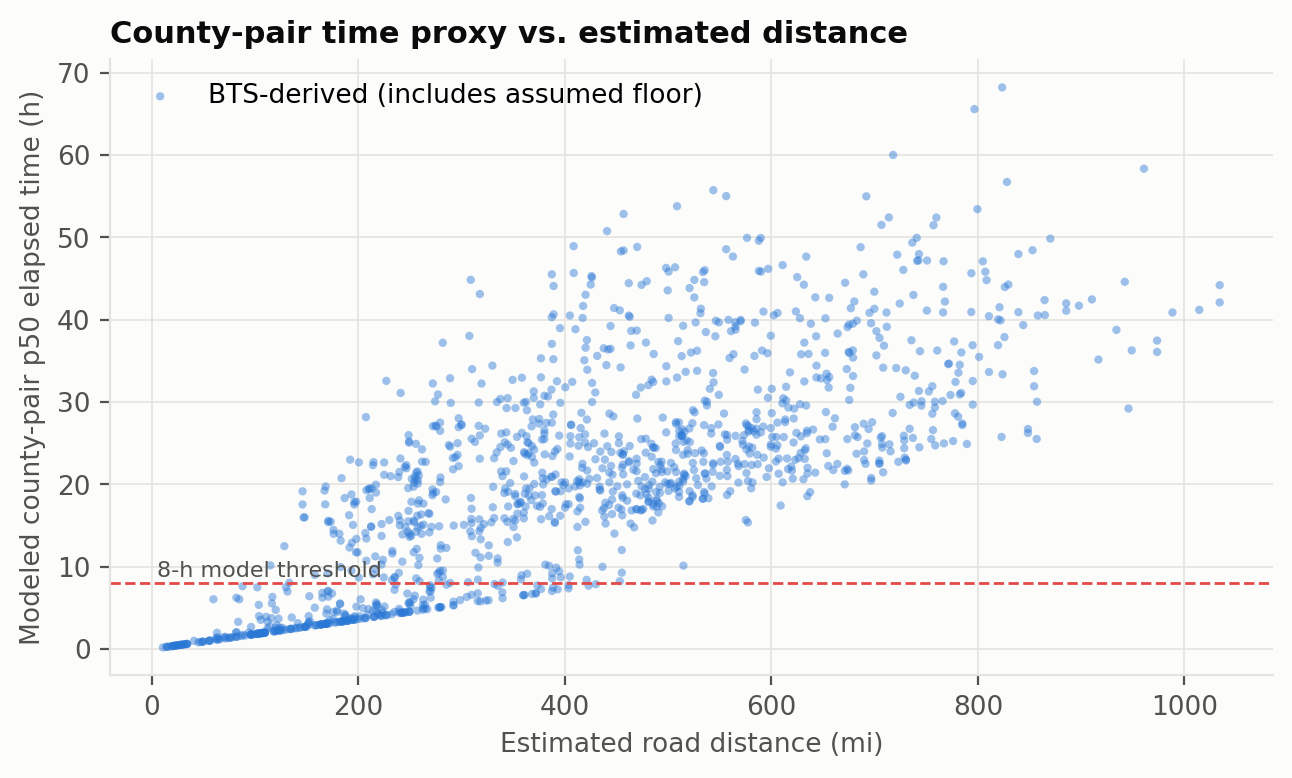

In [5]:
show("fig_travel_time.png", 750)

### Observations: Step 1

- The study includes **60 demand counties**, **22 candidate
  center counties**, and **1,320 county-pair routes**. The population estimates
  sum to **36,122,211 residents**; the assumed demand rate converts this to
  **54,183.3 pallets per week**.
- BTS source records cover **98.5%** of the route pairs.
  **180** source rows were adjusted by the assumed time floor.
  The **20** missing local pairs use an assumed 30 minutes;
  **0** nonlocal pairs required regression imputation.
- The reported distance–time correlation is **0.77** for
  the nonlocal BTS-derived time proxies. Distance alone therefore does not describe
  all variation in the modeled time values.
- The source-verification record reports matching values for the compared Census and
  BTS inputs. This supports their provenance; it does not turn assumed pallet demand,
  facility capacities, or county location proxies into observed company measurements.

## Step 2: Prior knowledge and operational assumptions

The truck benchmark is $2.270/mile for 2023 from ATRI's 2024 update. It is a historical
operating-cost average, not a freight quote. Other economic inputs are assumptions.

The 35%–90% throughput band also bounds normalized cycle stock under a common
one-week ordering cycle: average cycle stock is half weekly throughput. It does not
optimize multi-period inventory. Approximate safety stock includes assumed county
and shared regional variation; holding cost is excluded from the network objective.

### Cost, capacity, and demand assumptions

In [6]:
display(pd.DataFrame({"parameter": S["run"]["parameters"].keys(),
                      "value": [str(v) for v in S["run"]["parameters"].values()]}))
display(table("candidates.csv"))


,parameter,value
0,truck_cost_per_mile,2.27
1,pallets_per_truck,26
2,outbound_load_factor,0.7
3,inbound_deadhead,0.15
4,circuity,1.2
5,handling_cost,6.0
6,pallets_per_1000_pop,1.5
7,demand_cv,0.25
8,common_demand_cv,0.08
9,capacity,"{'large': 12000, 'small': 7000}"


,dc,fips,warehouse_estab_cbp2022,warehouse_emp_cbp2022,tier,capacity_pallets_wk,fixed_cost_wk,density_per_sqmi,inbound_miles_from_port,open_in_milp
0,"Jefferson, AL",1073,55.0,2554.0,small,7000.0,34590.0,603.0,414.0,True
1,"Mobile, AL",1097,30.0,3309.0,large,12000.0,53016.0,336.0,511.0,False
2,"Montgomery, AL",1101,26.0,2056.0,small,7000.0,33399.0,289.0,358.0,False
3,"Duval, FL",12031,109.0,10519.0,large,12000.0,58924.0,1321.0,149.0,False
4,"Leon, FL",12073,8.0,29.0,small,7000.0,33979.0,442.0,258.0,True
5,"Miami-Dade, FL",12086,213.0,5092.0,large,12000.0,59480.0,1413.0,524.0,False
6,"Orange, FL",12095,111.0,5879.0,large,12000.0,60571.0,1595.0,292.0,True
7,"Polk, FL",12105,63.0,12064.0,large,12000.0,53539.0,423.0,335.0,True
8,"Bibb, GA",13021,18.0,1410.0,small,7000.0,34685.0,628.0,190.0,False
9,"Chatham, GA",13051,83.0,3779.0,large,12000.0,55134.0,689.0,0.0,True


### Observations: Step 2

- The assumed loading and empty-mileage factors convert the historical truck-cost
  benchmark into **\$0.1247 per outbound pallet-mile** and
  **\$0.1004 per inbound pallet-mile**.
- The candidate centers have **214,000 pallets/week** of
  assumed rated capacity, about **3.95
  times** nominal demand. Aggregate capacity does not establish whether suitable
  centers can serve each county within the time screen.
- Only **24.8%** of candidate-to-customer arcs pass the
  **8-hour modeled median-time threshold**. Location
  choices must therefore account for the geographic pattern of allowable arcs.
- The **35%–90%** throughput band controls
  utilization. Under the common **1-week** ordering
  cycle, it also bounds normalized cycle stock. Stock conservation and replenishment
  over time are outside this model, and reported holding cost is outside its objective.

## Step 3: Model development

With binary openings $y_i$ and continuous demand shares $x_{ij}$, minimize
$$\sum_i f_i y_i + \sum_{ij} c_{ij} d_j x_{ij}.$$
The constraints are $\sum_i x_{ij}=1$,
$0.35K_i y_i\leq\sum_j d_jx_{ij}\leq0.90K_i y_i$,
$x_{ij}\leq y_i$, and $x_{ij}=0$ when the modeled median exceeds 480 minutes.
Here $c_{ij}$ includes inbound transport, handling, and outbound transport.
Split sourcing and fractional aggregate pallet flows are allowed.

The MILP provides the reference; the LP relaxation supplies a lower bound.
Rounding opens every positive LP location and reoptimizes flows. Greedy ADD/DROP and
simulated annealing search location sets using LP routing scores. Search penalties
allow infeasible intermediate networks; final feasibility is audited separately.

The gradient method fits continuous points with Adam and capacity-price updates,
then assigns them to distinct counties. Its Lagrangian includes
$-C\sum_k\mu_k$. A local repair search reduces unmet demand and minimum-throughput
deficits by opening or closing centers. The repaired result combines continuous
fitting with discrete local search and has no global optimality guarantee.

### LP results and comparison of optimization methods

In [7]:
display(pd.DataFrame([S["lp_relaxation"]]))
comparison = table("model_comparison.csv")
methods = comparison.set_index("method")
benchmark = methods.loc["Baseline (6 metro hubs)"]
add, drop = methods.loc["Greedy ADD"], methods.loc["Greedy DROP"]
annealing = methods.loc["Simulated annealing"]
rounded = methods.loc["LP relaxation + rounding"]
snap = methods.loc["Gradient (snap only)"]
repaired = methods.loc["Gradient (snap + repair)"]
modeled_saving = 1 - optimum["network_cost"] / benchmark.network_cost
display(comparison[["method", "n_dcs", "network_cost", "transport_cost", "unmet_pallets",
                    "balance_shortfall", "feasible_base_model", "gap_vs_milp_pct", "runtime_s"]])


,objective,runtime_s,fractional_y,integrality_gap_pct
0,2.884609e+06,0.0256,5,0.152412


,method,n_dcs,network_cost,transport_cost,unmet_pallets,balance_shortfall,feasible_base_model,gap_vs_milp_pct,runtime_s
0,MILP (exact),8,2.889006e+06,2.190980e+06,0.0,0.0,True,-1.110223e-14,0.228288
1,LP relaxation + rounding,11,2.988062e+06,2.137615e+06,0.0,0.0,True,3.428714e+00,0.042783
2,Greedy ADD,7,2.918129e+06,2.229733e+06,0.0,0.0,True,1.008069e+00,1.626587
3,Greedy DROP,10,2.907404e+06,2.145314e+06,0.0,0.0,True,6.368299e-01,4.702894
4,Simulated annealing,8,2.889006e+06,2.190980e+06,0.0,0.0,True,2.220446e-14,17.441220
5,Gradient (snap only),10,3.143046e+06,2.307579e+06,0.0,0.0,True,8.793354e+00,53.362690
6,Gradient (snap + repair),8,2.889006e+06,2.190980e+06,0.0,0.0,True,2.220446e-14,53.362690
7,Baseline (6 metro hubs),6,3.378578e+06,2.712804e+06,0.0,0.0,False,NaN,0.016417


#### Selected distribution network

County location proxies and weekly pallet assignments show the selected network.
The connecting lines represent allocations rather than actual road routes.

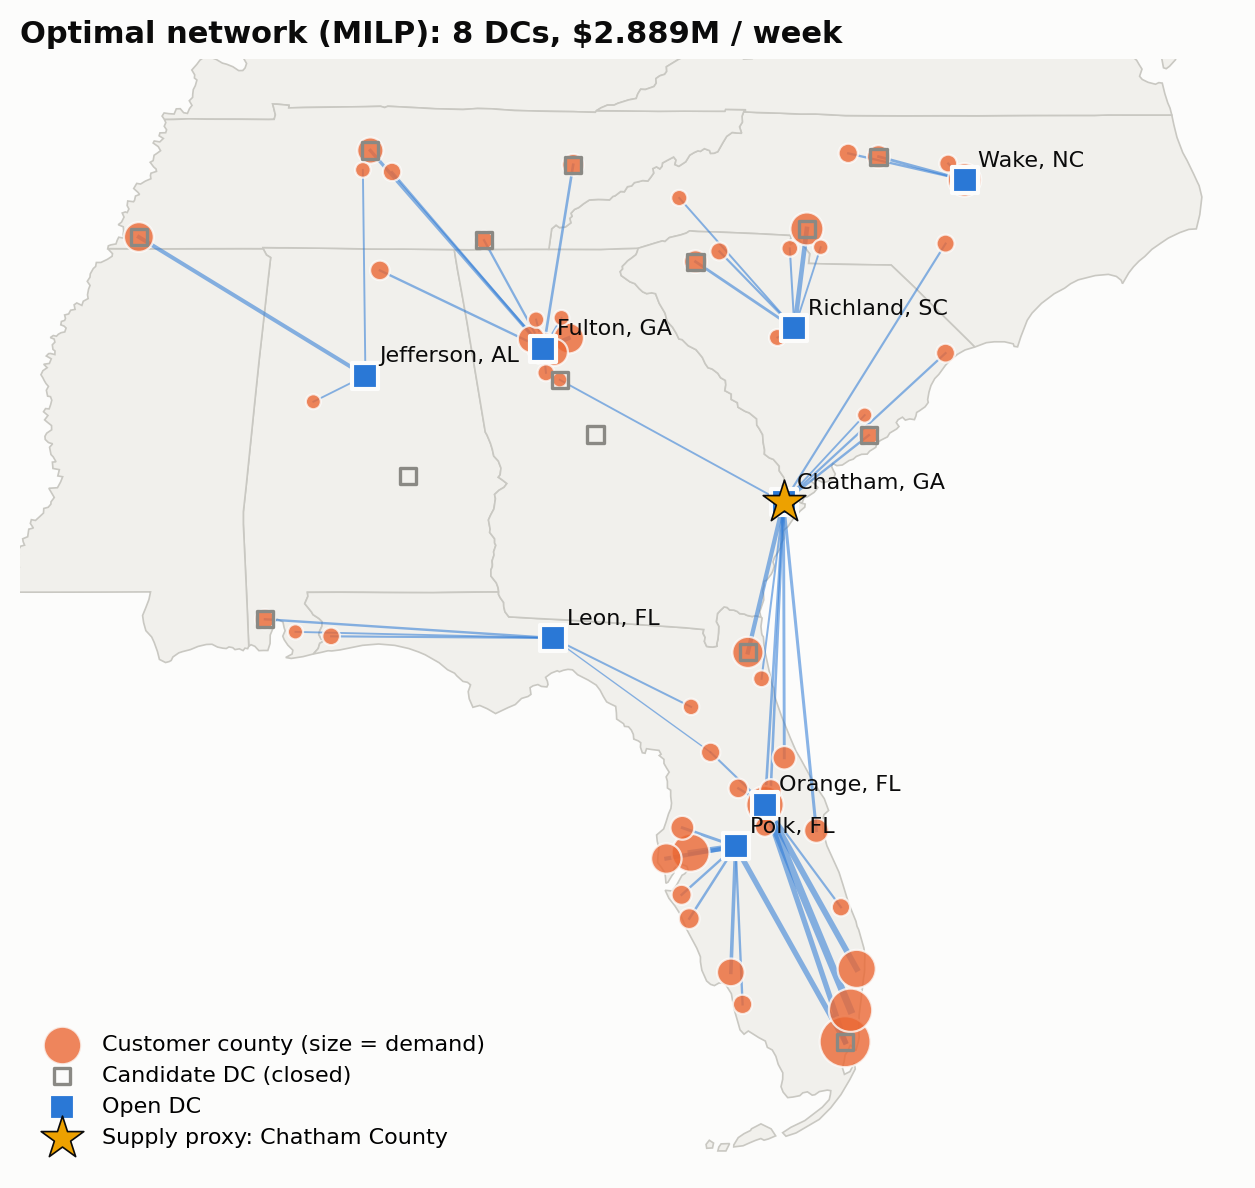

In [8]:
show("fig_network_map.png", 750)

#### Comparison of optimization costs and runtimes

Cost gaps relative to the MILP reference and recorded computation times are shown
for the solutions that pass the base-model feasibility checks.

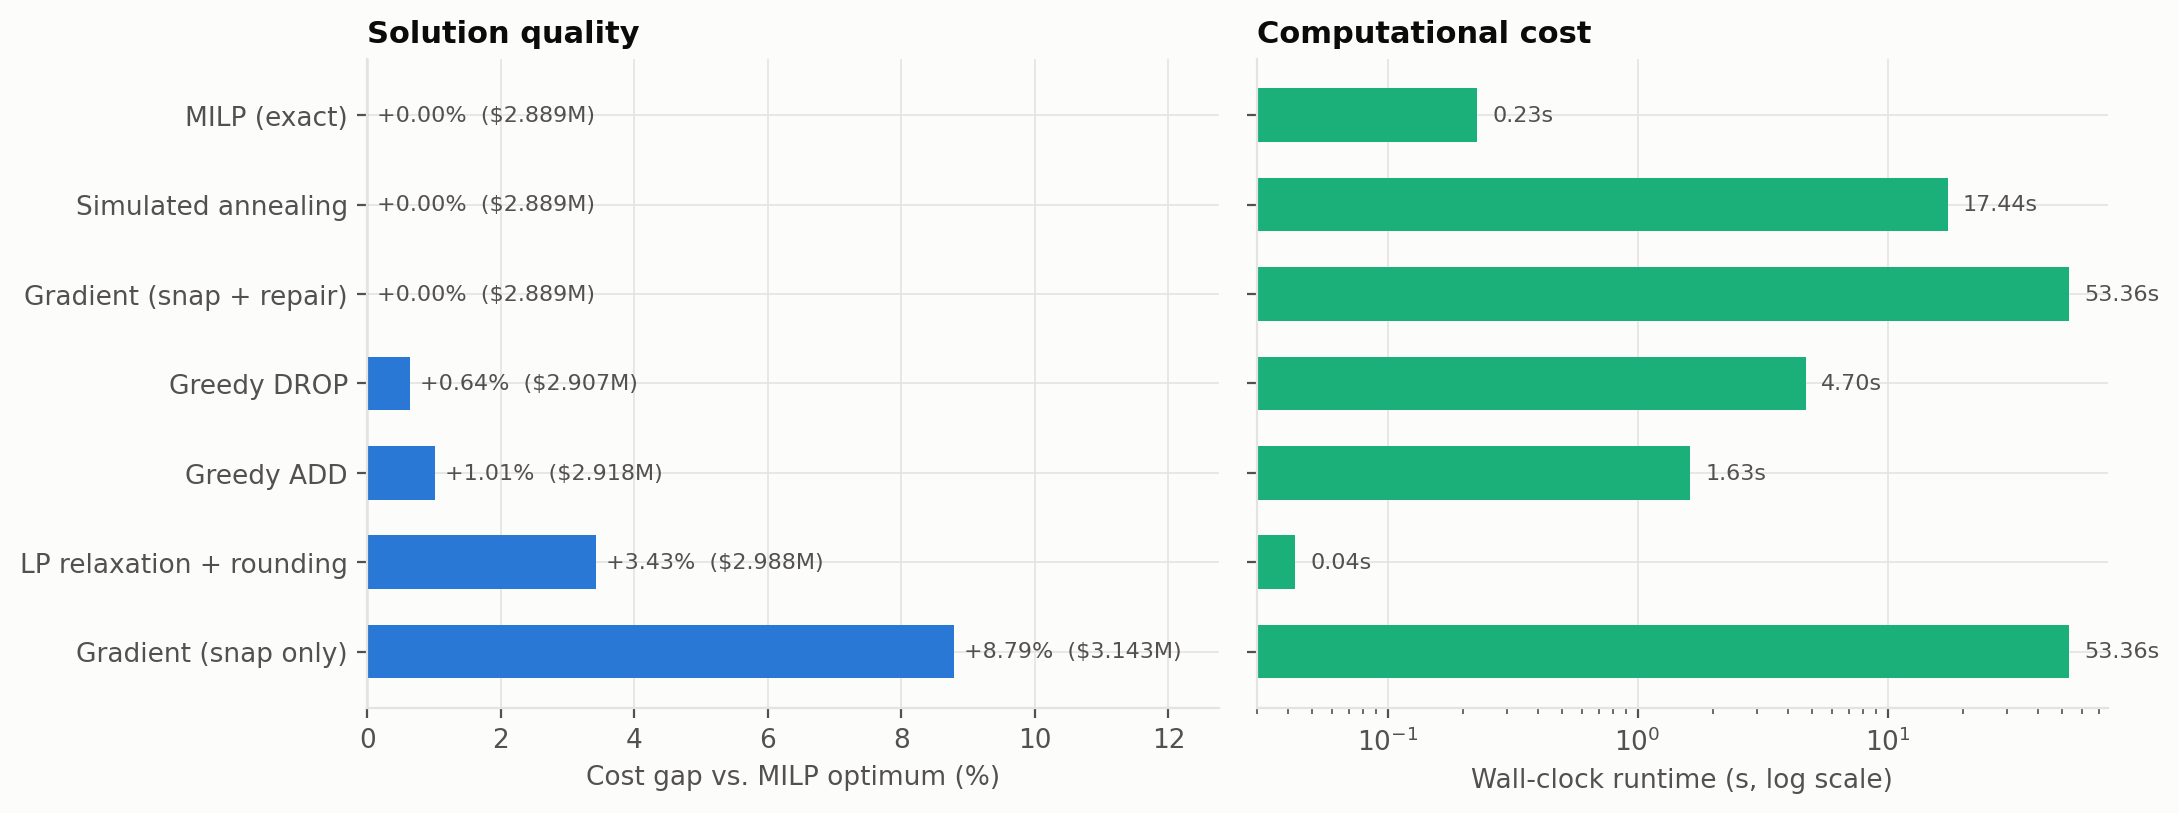

In [9]:
show("fig_model_comparison.png")

#### Continuous location trajectories and gradient objective

The map traces the fitted continuous sites and the snapped, repaired locations.
The objective trace uses changing temperatures and capacity prices.

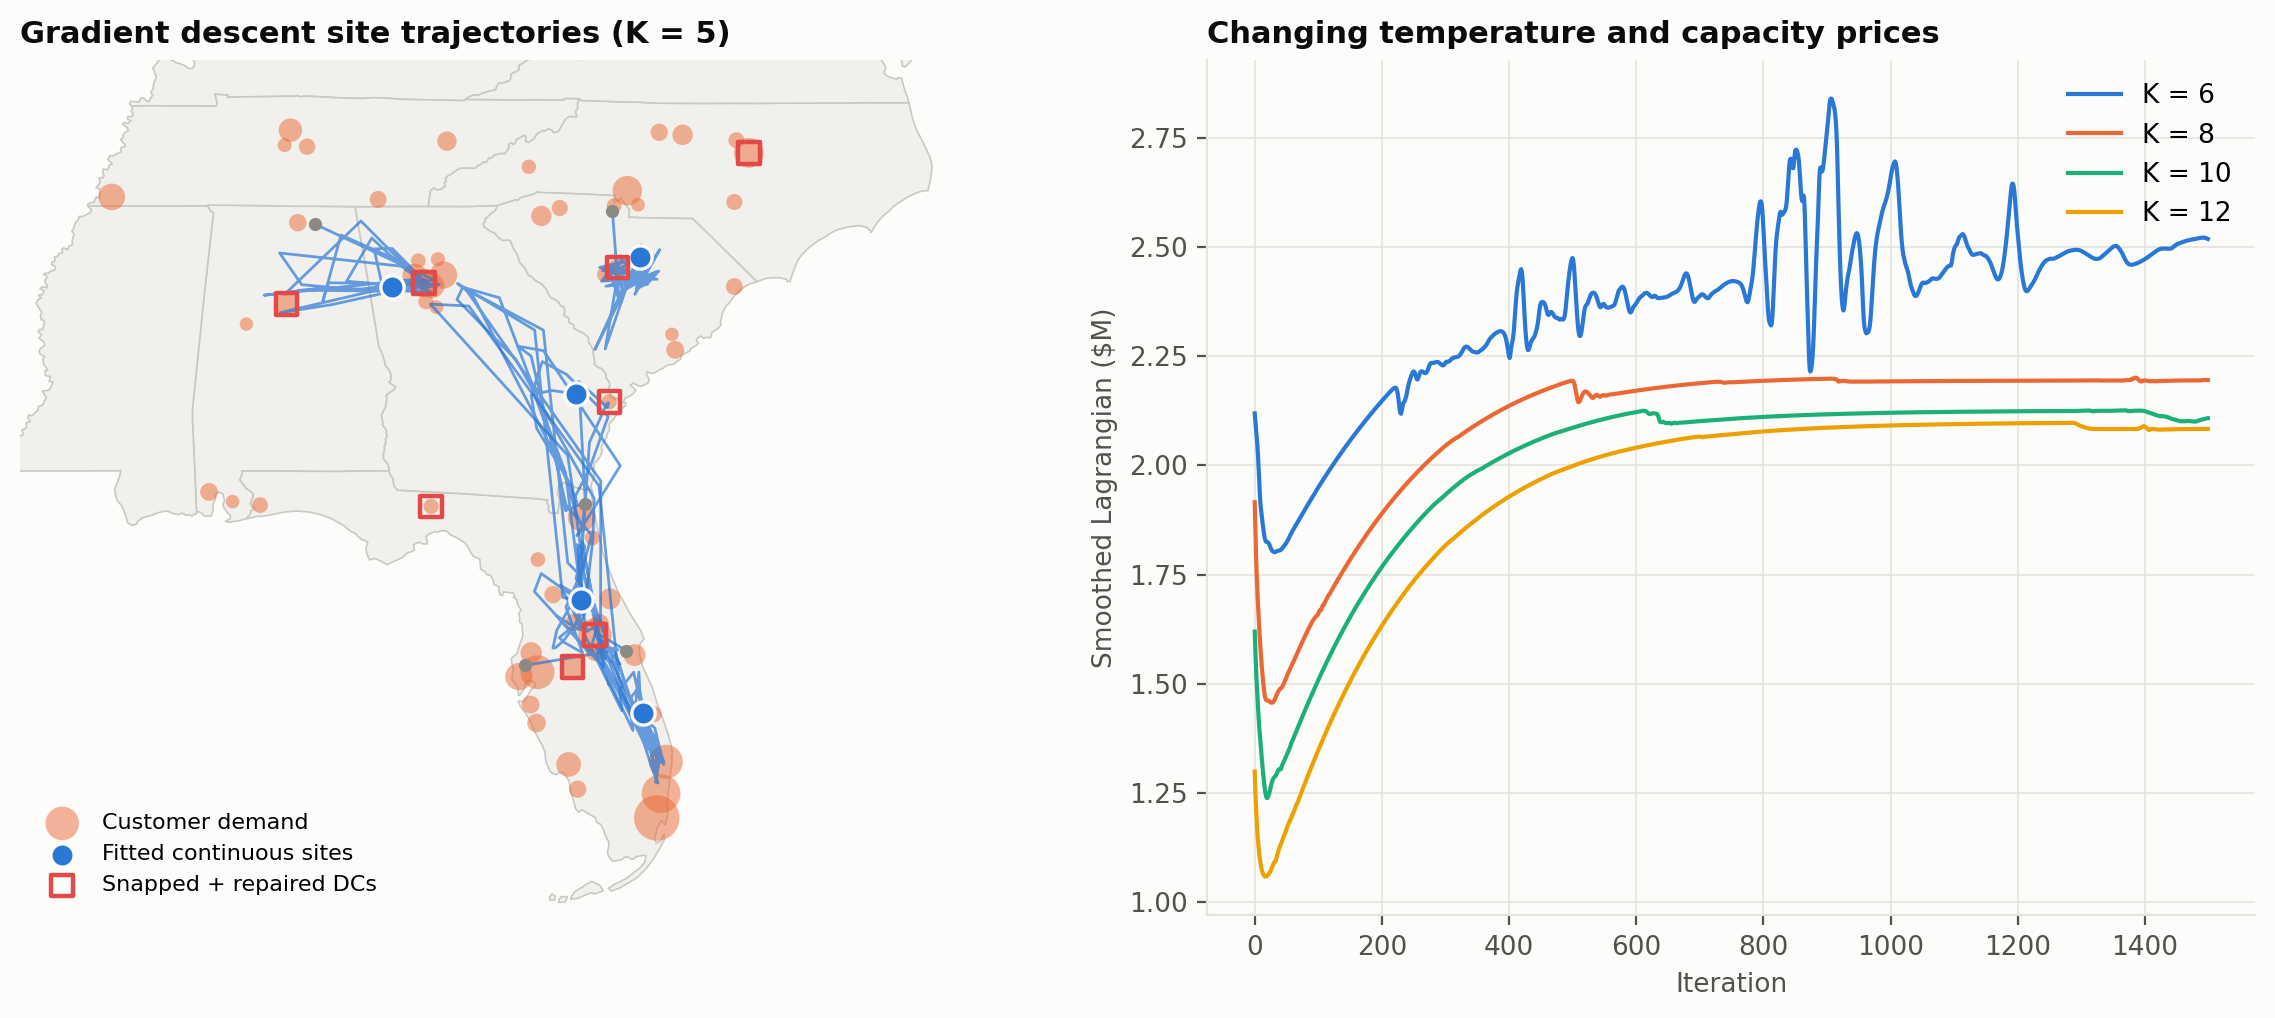

In [10]:
show("fig_gradient.png")

### Observations: Step 3

- The MILP selects **8 centers** at **\$2,889,006/week**
  (**\$53.32/pallet**). Its recorded solve time is
  **0.228 seconds**, with a reported gap of **0**.
- The LP relaxation gives a lower bound of **\$2,884,609/week**;
  the MILP exceeds that bound by **0.152%**.
  Opening every positive LP location yields **11 centers** and a
  **3.43%** cost gap after routing.
- Greedy ADD selects **7 centers** at **1.01%** above
  the MILP cost; greedy DROP selects **10** at **0.64%** above it.
  Simulated annealing finishes **0.00%** from the reference
  in **17.44 seconds** for this seeded run.
- Gradient fitting with snapping alone finishes **8.79%** above
  the MILP. The result with discrete local repair finishes
  **0.00%** from it. The shared search takes
  **53.36 seconds**; the repaired result includes both continuous
  fitting and opening/closing moves, so it does not certify the continuous method.
- The selected design costs **14.5%** less than the assumed six-hub
  comparison. That comparison routes only **82.6%** of
  volume on arcs that pass the time screen and is not a feasible base-model alternative.

## Step 4: Validation

Each network is checked for demand, capacity, minimum throughput, the time screen,
open-center shipments, and nonnegative flows. The assumed six-hub comparison ignores
the time screen and is excluded from feasible base-model rankings.

Reduced enumeration uses a hard-constrained transportation LP for every nonempty
open set. It validates the reduced instance only. Full-instance optimality relies on
the MILP termination status and solver bound. Tests also check marginal costs against
small cost changes, analytic gradients, and repair of throughput deficits.

### Feasibility audit and reduced-instance enumeration

In [11]:
audit = table("feasibility_audit.csv")
display(audit)
display(pd.DataFrame([S["brute_force"]]))
enumeration = S["brute_force"]
validated = solve_cflp(inst)
assert all(check_feasibility(inst, validated).values())
assert np.isclose(validated.objective, S["milp"]["network_cost"], rtol=1e-8)
print("Saved optimal cost matches a fresh MILP solve.")


,method,demand_met,capacity,balance,sla,only_open_dcs_ship,non_negative
0,MILP (exact),True,True,True,True,True,True
1,LP relaxation + rounding,True,True,True,True,True,True
2,Greedy ADD,True,True,True,True,True,True
3,Greedy DROP,True,True,True,True,True,True
4,Simulated annealing,True,True,True,True,True,True
5,Gradient (snap only),True,True,True,True,True,True
6,Gradient (snap + repair),True,True,True,True,True,True


,candidates,customers,subsets,feasible_subsets,enumeration_cost,milp_cost,same_network,rel_diff,enumeration_s,milp_s
0,12,58,4095,90,2.851568e+06,2.851568e+06,True,4.899003e-16,47.033121,0.024564


Saved optimal cost matches a fresh MILP solve.


### Observations: Step 4

- **7 of 7** optimized
  solutions pass every independent constraint check. Feasibility is assessed from
  the actual flows, separately from whether an algorithm produced a finite search score.
- Reduced enumeration examines **4,095** nonempty networks for
  **12 candidate counties** and **58 demand counties**;
  **90** networks are feasible. Its minimum cost is
  **\$2,851,567.72**, versus
  **\$2,851,567.72** for the reduced MILP, a relative difference of
  **4.9e-16**.
- Enumeration takes **47.03 seconds**, compared with
  **0.025 seconds** for the reduced MILP on this run. The full-instance
  result was also checked against a fresh solve in the preceding cell.
- Agreement on the reduced problem supports implementation correctness. Full-instance
  optimality still rests on the solver status and bound; it does not validate the
  assumed demand, costs, capacities, or delivery-time proxy against company operations.

## Step 5: Iteration

The first four models successively add capacity, the time screen, and minimum
throughput. The fifth requires a single center per county. Cost differences describe
this instance. Site counts need not change monotonically as constraints are added.

### Results as operational constraints are added

In [12]:
iterations = table("iterations.csv")
display(iterations[["version", "n_dcs", "network_cost", "pct_within_sla_p50", "util_cv"]])
v1, v2, v3, v4, v5 = [iterations.iloc[i] for i in range(5)]


,version,n_dcs,network_cost,pct_within_sla_p50,util_cv
0,v1 Uncapacitated,3,2.713045e+06,0.734633,0.241438
1,v2 + Capacity,6,2.806453e+06,0.716270,0.139642
2,v3 + Delivery-time SLA,9,2.883343e+06,1.000000,0.353382
3,v4 + Minimum throughput (base),8,2.889006e+06,1.000000,0.296738
4,v5 + Single sourcing,9,2.895986e+06,1.000000,0.320282


#### Effect of adding operational constraints

The panels compare optimal weekly cost, selected center counts, and the share of
assigned volume on arcs that pass the modeled time screen across model versions.

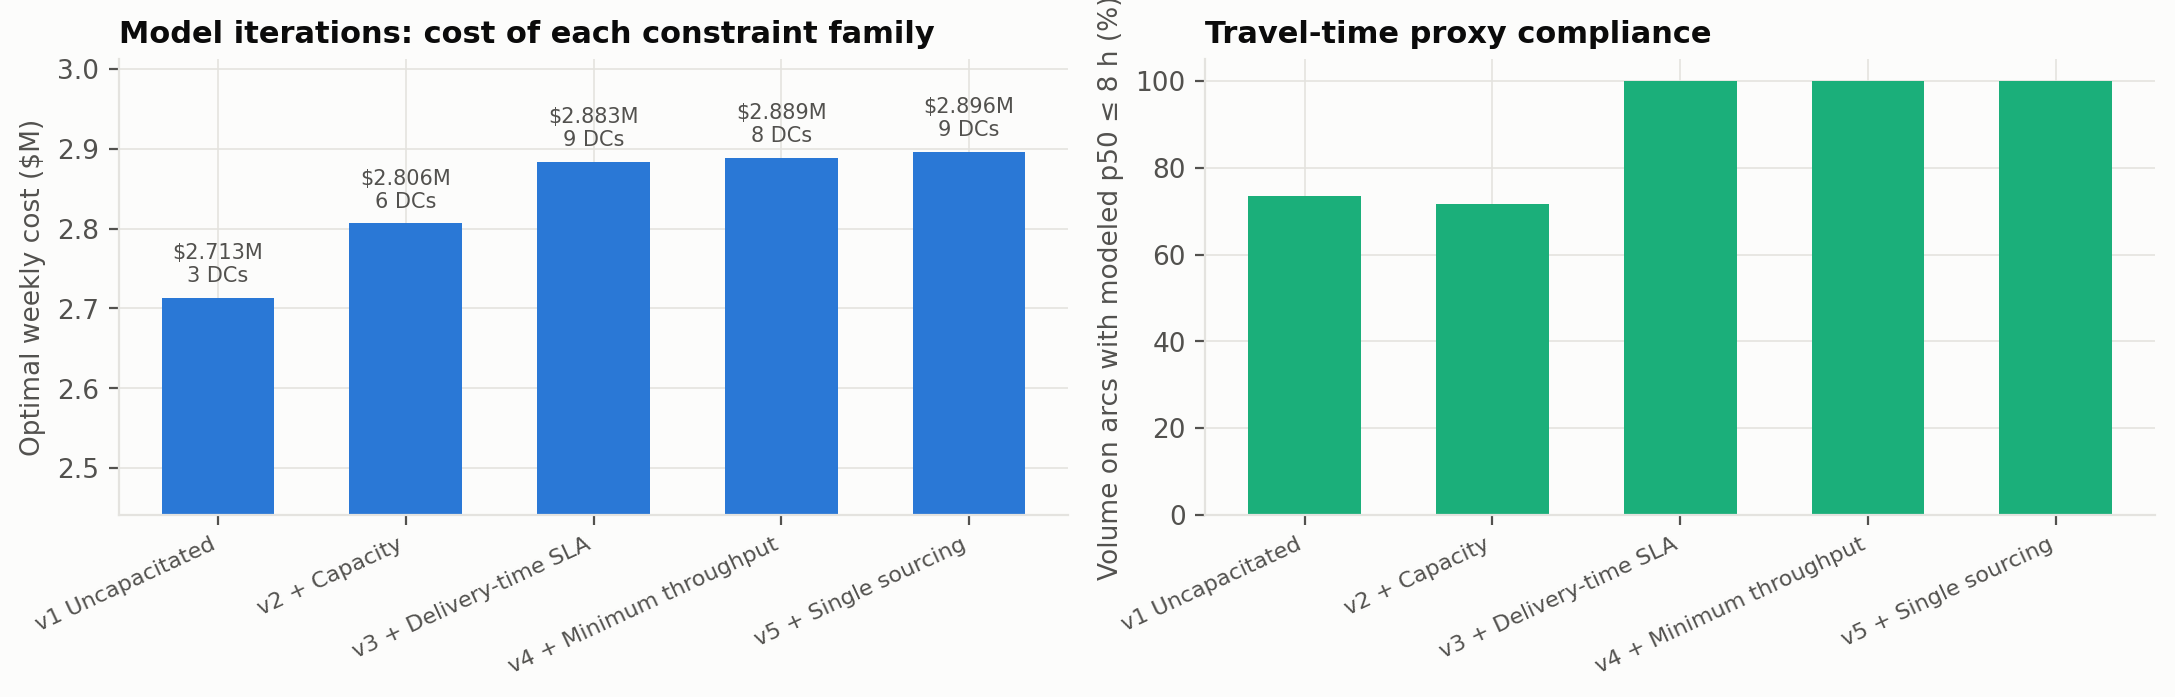

In [13]:
show("fig_iterations.png")

### Inventory policy indicators

Cycle stock and approximate safety stock are calculated from the selected flows
under the stated inventory policy.

In [14]:
display(table("inventory_policy.csv"))

,dc,open,throughput,utilization,cycle_stock,safety_stock_approx
0,"Jefferson, AL",True,3120.8760,0.445839,1560.43800,596.641302
1,"Leon, FL",True,2450.0000,0.350000,1225.00000,385.777613
2,"Orange, FL",True,10800.0000,0.900000,5400.00000,1669.642505
3,"Polk, FL",True,10800.0000,0.900000,5400.00000,1536.592103
4,"Chatham, GA",True,8025.2440,0.668770,4012.62200,1054.586018
5,"Fulton, GA",True,10075.4910,0.839624,5037.74550,1329.616086
6,"Wake, NC",True,3615.2115,0.516459,1807.60575,687.555354
7,"Richland, SC",True,5296.4940,0.756642,2648.24700,810.846667


### Observations: Step 5

- The uncapacitated model opens **3 centers** at **\$2,713,045/week**,
  but only **73.5%** of assigned volume uses arcs that pass the
  eight-hour time screen. Its capacity utilization is unconstrained.
- Adding capacity increases the selected count to **6** and cost to
  **\$2,806,453/week**. The share on time-eligible arcs is
  **71.6%**; capacity constraints alone do not enforce the time screen.
- Adding the time screen selects **9 centers** and raises cost by
  **2.74%**. The flow-weighted average of arc median
  proxies falls from **6.47** to **1.94 hours**.
- The minimum-throughput rule changes the design to **8 centers** at
  **0.20%** additional cost. Utilization CV falls
  from **0.353** to **0.297**, although inventory dispersion is not
  directly optimized.
- Requiring one center per customer county selects **9 centers** and adds
  **0.24%** to base-model cost. This quantifies
  the scenario-specific price of simplifying sourcing assignments.

## Step 6: Sensitivity, simulation, and reporting

Sweeps change one parameter at a time. Capacity increases also raise minimum
throughput. Circuity changes cost distances while the main time matrix stays fixed.

LP marginal values hold the open centers fixed. Relaxing usable capacity differs
from increasing rated capacity, which changes both throughput bounds. Demand values
come from a pallet-flow LP with demand as a right-hand side. They are local LP
sensitivities, not dual prices of discrete warehouse decisions.

The paired simulation uses mean-one lognormal county and regional shocks, reallocates
flows, and prices unmet demand at $500/pallet. These are synthetic scenarios. A zero
shortage count does not prove zero shortage risk.

### Sensitivity, capacity, and demand-simulation tables

In [15]:
tornado = table("tornado.csv")
capacity_values = table("capacity_shadow_prices.csv")
expansion_candidates = "; ".join(capacity_values.loc[capacity_values.capacity_shadow_price > 1e-6, "dc"])
simulation = table("monte_carlo_summary.csv")
effects = tornado.set_index("parameter")
nominal, hedged = simulation.iloc[0], simulation.iloc[1]
display(tornado)
display(capacity_values)
display(simulation)


,parameter,low,high,span
0,DC capacity,0.008437,-0.001899,0.010335
1,Handling cost,-0.022506,0.022506,0.045012
2,DC fixed cost,-0.027283,0.025817,0.053100
3,Outbound load factor,0.050994,-0.053344,0.104338
4,Circuity factor,-0.151677,0.150426,0.302103
5,Truck cost per mile,-0.151677,0.150426,0.302103
6,Demand volume,-0.180513,0.178919,0.359432


,dc,open,throughput,capacity,utilization,usable_capacity_shadow_price,capacity_shadow_price
0,"Jefferson, AL",True,3120.8760,7000.0,0.445839,0.000000,0.000000
1,"Leon, FL",True,2450.0000,7000.0,0.350000,0.000000,-1.362013
2,"Orange, FL",True,10800.0000,12000.0,0.900000,7.105917,6.395326
3,"Polk, FL",True,10800.0000,12000.0,0.900000,5.812688,5.231419
4,"Chatham, GA",True,8025.2440,12000.0,0.668770,0.000000,0.000000
5,"Fulton, GA",True,10075.4910,12000.0,0.839624,0.000000,0.000000
6,"Wake, NC",True,3615.2115,7000.0,0.516459,0.000000,0.000000
7,"Richland, SC",True,5296.4940,7000.0,0.756642,0.000000,0.000000


,network,mean_cost,p95_cost,mean_network_cost,mean_fill_rate,p05_fill_rate,prob_shortage,n_dcs,fixed_cost
0,MILP optimum (nominal demand),2.884375e+06,3.323672e+06,2.882576e+06,0.999947,1.0,0.006,8,372925.951608
1,Hedged MILP (+15 % demand),2.896231e+06,3.292234e+06,2.896231e+06,1.000000,1.0,0.000,9,430759.053511


#### Sensitivity of network cost to model inputs

Each panel reoptimizes the network while changing one input. Point labels give
the number of open centers.

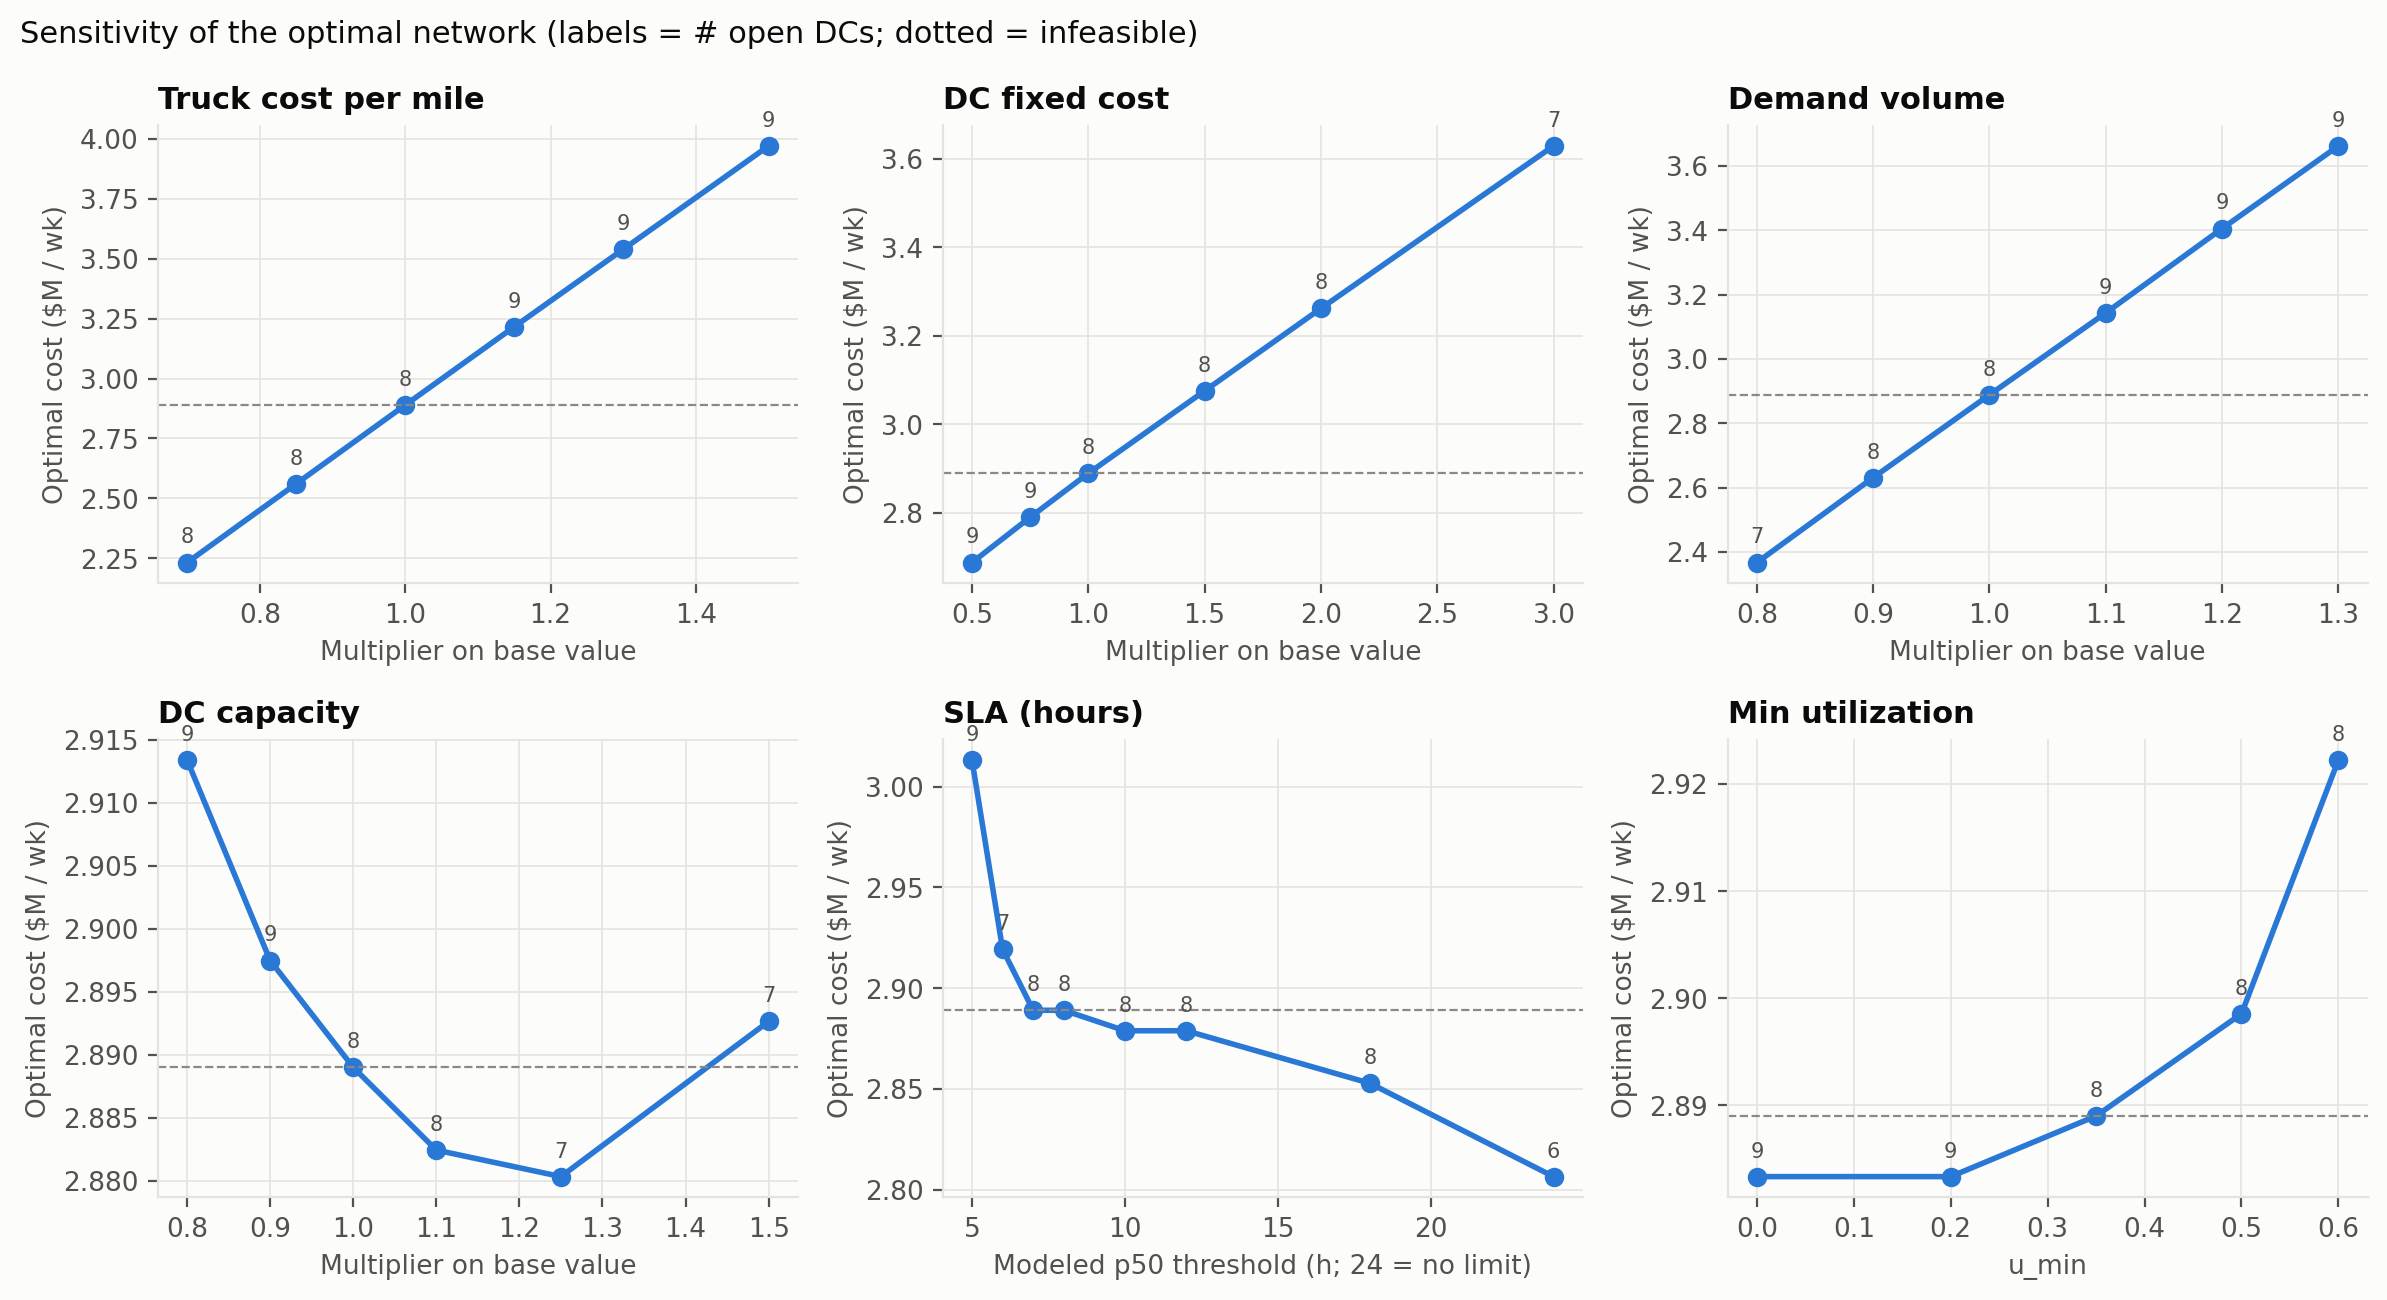

In [16]:
show("fig_sensitivity.png")

#### Demand marginal costs and capacity shadow prices

The map shows local demand marginal costs, and the bars show local rated-capacity
savings from the LP with the open-center set held fixed.

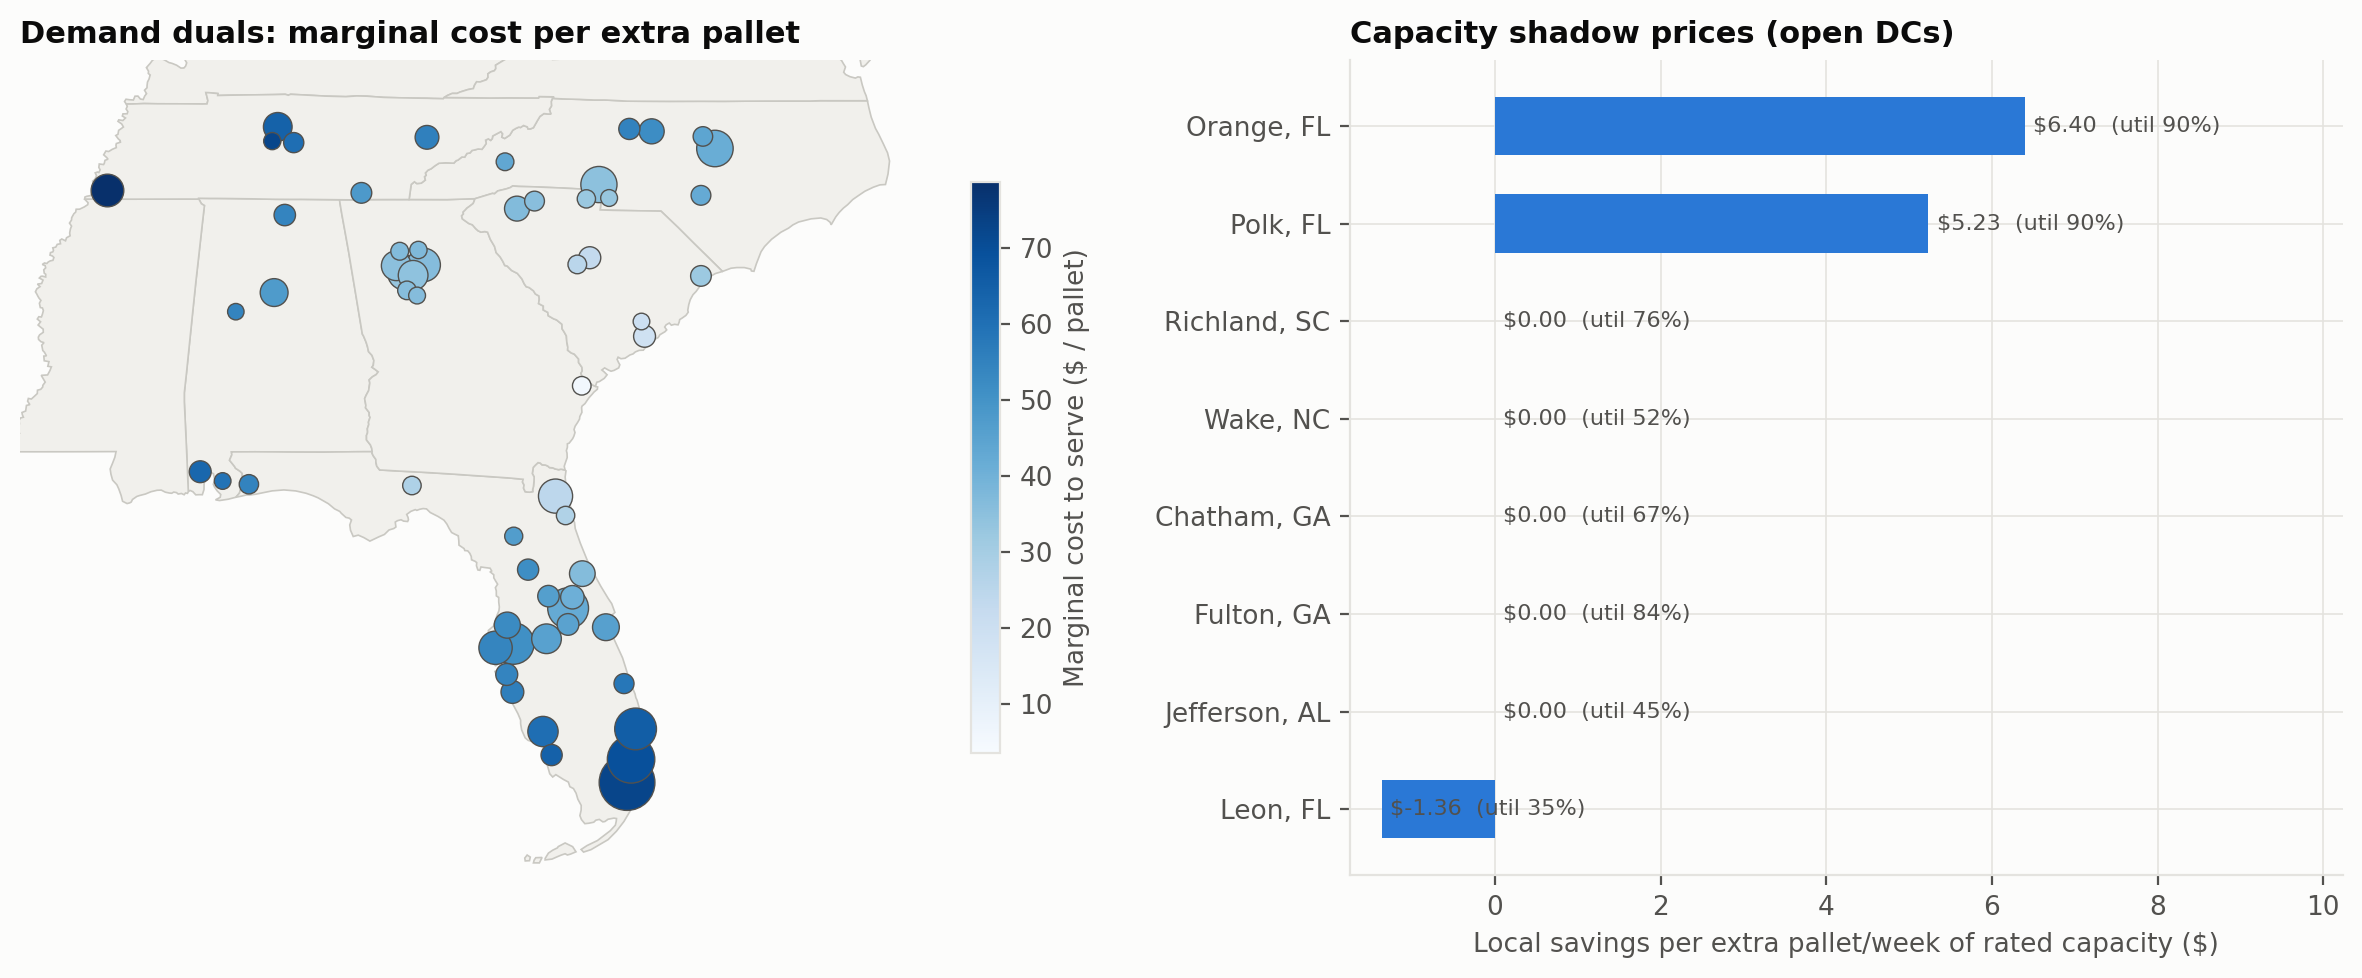

In [17]:
show("fig_shadow_prices.png")

#### Demand-simulation costs and fill rates

The distributions compare the nominal design with the design for 15% higher demand
under the assumed demand shocks. Fill rates measure quantities served on allowed arcs.

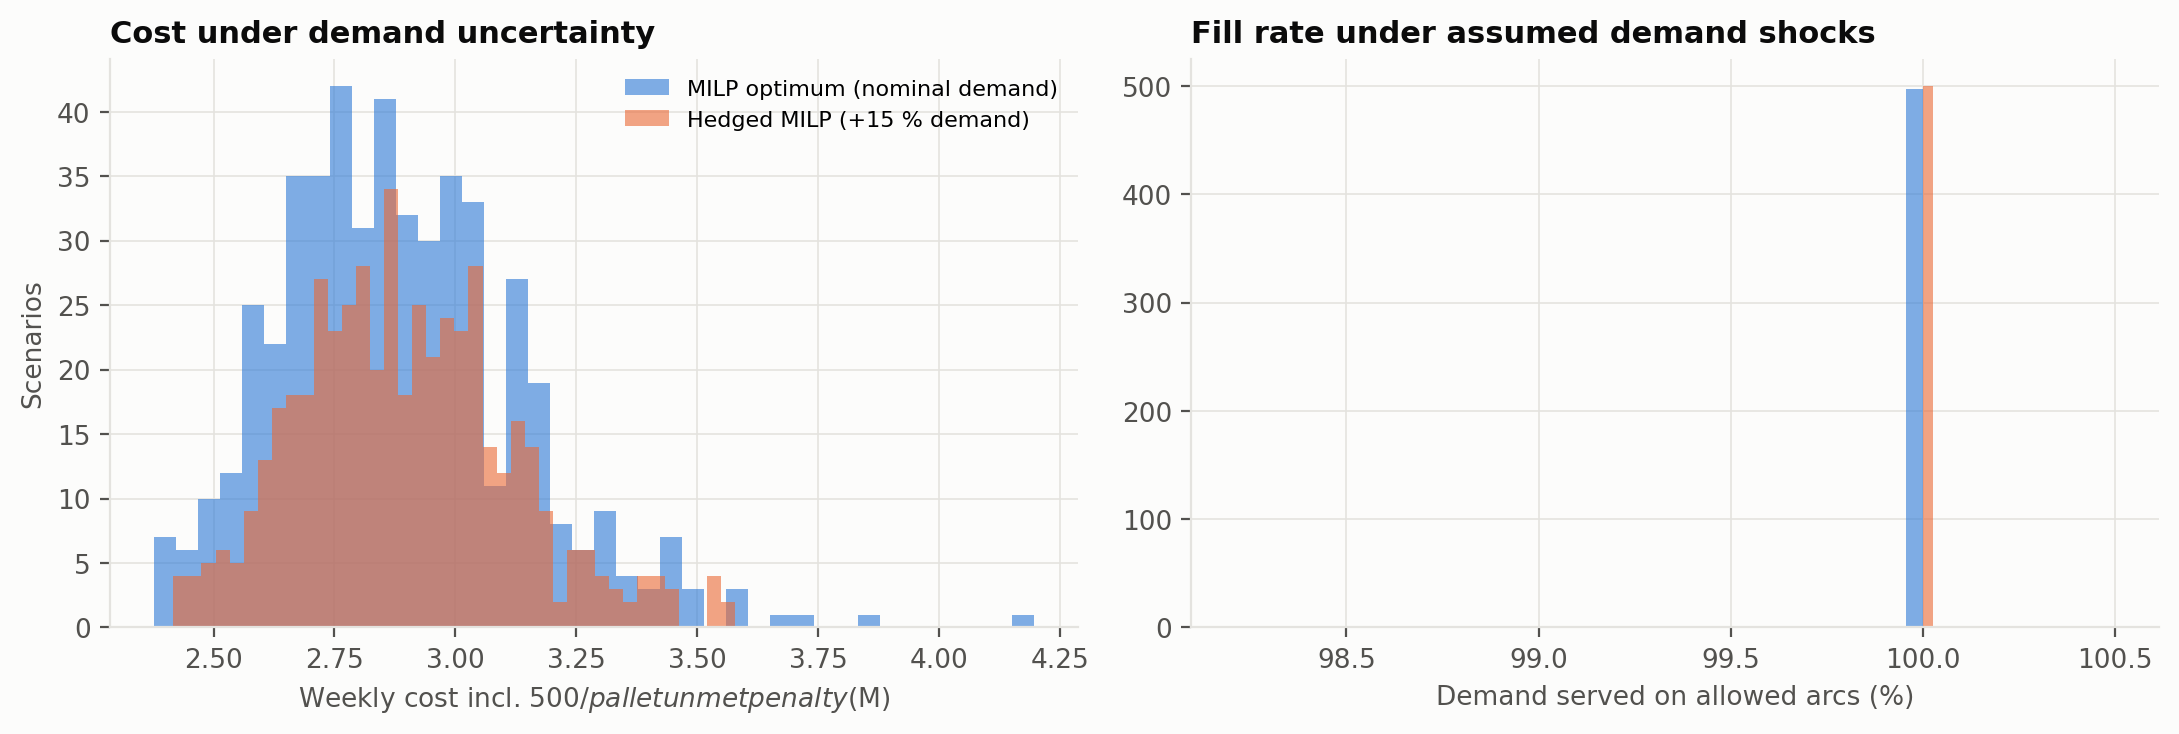

In [18]:
show("fig_monte_carlo.png")

### Observations: Step 6

- A 20% demand reduction changes reoptimized cost by
  **-18.05%**; a 20% increase changes it by
  **+17.89%**. Corresponding truck-cost effects are
  **-15.17%** and
  **+15.04%**. Demand and transportation inputs
  therefore have larger tested cost effects than fixed costs or handling.
- A 20% improvement in assumed outbound load factor changes network cost by
  **-5.33%** after reoptimization. This is a
  scenario result; the model does not construct delivery routes to achieve that loading.
- The rated-capacity marginal savings are positive at
  **Orange, FL: \$6.40; Polk, FL: \$5.23**
  per additional pallet/week of rated capacity. These are local values for the fixed
  network and include changes to both throughput bounds.
- Across **500** scenarios, the nominal design has mean
  fill **99.995%** and more than one unmet pallet in
  **0.6%** of scenarios. The design for 15% higher demand uses
  **9 centers**, with mean fill **100.000%** and
  **0.0%** sampled shortage frequency, at
  **+0.41%** mean penalized cost.
- These fill rates concern quantities served on allowable arcs under assumed demand
  shocks. They are neither measured delivery punctuality nor a simulation of the
  inventory policy; zero sampled shortages would not establish zero future risk.

## Final insights and recommendations

### Final insights

- **Network choice:** The selected **8-center** design consists of
  **Jefferson, AL; Leon, FL; Orange, FL; Polk, FL; Chatham, GA; Fulton, GA; Wake, NC; Richland, SC**. It costs **\$2,889,006/week**, including
  **\$2,190,980** in transportation, under the defined scenario.
- **Modeled improvement:** Cost is **14.5%** below the assumed six-hub
  comparison. All selected flows use time-eligible arcs; the comparison's eligible
  share is **82.6%**. The difference is not documented
  savings or an on-time delivery improvement for an operating company.
- **Method choice:** The MILP provides the certified reference for this candidate list.
  Simulated annealing and gradient fitting with local repair finish
  **0.00%** and **0.00%** from
  it in these runs. Greedy ADD and DROP finish within **1.01%**.
- **Operating trade-offs:** Inbound transportation represents
  **47.3%** of network cost. The time screen
  changes the design materially, while a minimum-throughput policy reduces
  utilization dispersion in this instance. Neither policy directly optimizes
  actual delivery reliability or multi-period inventory.

### Recommendations

1. **Investigate the selected counties as a shortlist.** Obtain actual property
   availability, addresses, lease costs, throughput and storage limits, and port
   drayage costs before choosing warehouse properties.
2. **Evaluate capacity where the marginal savings are positive.** The displayed table
   identifies **Orange, FL; Polk, FL**. Reoptimize with realistic
   expansion increments and costs before using local shadow prices for a larger change.
3. **Use the higher-demand design as a stress case.** Its **9-center**
   configuration has **0.0%** sampled shortage frequency at
   **+0.41%** mean penalized cost in this simulation.
   It supports further evaluation rather than an automatic opening or closing rule.
4. **Test load consolidation and inbound transport options.** Loading assumptions and
   transportation rates materially affect modeled cost. Check operational feasibility
   and carrier quotes before treating the tested savings as achievable.
5. **Connect validated forecasts to the optimizer.** Replace population-based pallet
   demand with forecasts fitted to customer orders. Evaluate forecasts and resulting
   plans on later periods, and estimate service distributions from dispatch and arrival
   records before defining delivery promises.
6. **Extend inventory planning when required.** Add time-indexed stock conservation,
   replenishment, storage limits, shortages, and holding cost. The present stock
   indicators reflect a stated policy rather than optimized replenishment decisions.

The matching [report](../report/Assignment3_Optimization_Report.md) provides the full
methodology, detailed results, limitations, and APA references.

## Conclusion

The analysis combines public Census and BTS inputs with stated logistics assumptions
to compare exact and approximate approaches to network design. For this scenario,
the MILP selects **8 centers** at **\$2,889,006 per week**,
or **\$53.32 per pallet**, while satisfying the modeled demand,
capacity, throughput, and median-time constraints. Its cost is **14.5%**
below the assumed six-hub comparison.

The LP lower bound, independent flow audits, reduced enumeration, and fresh solve
support the computational result. Heuristic and repaired gradient outcomes show that
alternative search methods can approach or match the reference in this instance,
without establishing general convergence or runtime superiority. Sensitivity analysis
identifies demand and transportation inputs as major tested cost drivers; paired
simulation illustrates the cost and shortage trade-off of a higher-demand design.

The business implication is to evaluate warehouse choices jointly with transport,
capacity, and service requirements. Operational use requires company orders,
property and carrier costs, trip-level delivery data, and a fuller inventory model.
The current result is a reproducible solution to the specified exercise, not a claim
of guaranteed real-world savings or delivery performance.